# Regresión: GLM Binomial Negativa

### Imports y Configuración

In [1]:
import sys
sys.path.append("/workspace/src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown

from EstiloGraficos import aplicar_estilo

# Misma paleta y estilo que el dashboard (components/plotly_theme.py)
aplicar_estilo()

# Textos largos completos en las tablas (criterio de selección, hiperparámetros)
pd.set_option("display.max_colwidth", None)

from ModeladoRegresion import (
    SEED, USAR_GPU, GPU_DISPOSITIVOS, NOMBRES_REG, VARIANTES, RUTA_FASE1_REG,
    cargar_split, separar_x_y_reg, crear_cv_reg, resumen_target, dispositivo_reg,
    ejecutar_fase1_reg, formatear_tabla_cv_reg, elegir_variante, guardar_fase1_reg, formatear_hiperparametros,
    pruebas_binomial_negativa, interpretar_razones, probabilidades_conteo, graficar_frecuencias_conteo,
)

CLAVE = "binomial_negativa"

In [2]:
pd.Series({
    "USAR_GPU": USAR_GPU,
    "GPU detectada por librería": ", ".join(f"{lib}: {disp}" for lib, disp in GPU_DISPOSITIVOS.items() if disp) or "ninguna",
    "Dispositivo de entrenamiento": dispositivo_reg(CLAVE),
}, name=NOMBRES_REG[CLAVE]).to_frame()

,GLM binomial negativa
USAR_GPU,False
GPU detectada por librería,ninguna
Dispositivo de entrenamiento,CPU


### Datos: Split y Folds

In [3]:
df = pd.read_csv('/workspace/data/raw/screen_time_mental_health.csv')

df_train, _ = cargar_split(df)   # el test no se usa en esta fase
X_train, y_train = separar_x_y_reg(df_train)
cv = crear_cv_reg(SEED)

resumen_target(y_train)

,Filas,Media,Mediana,DE,Asimetría,Ceros (%),BDI ≥ 14 (%)
Conjunto,,,,,,,
Train,3848,7.3,5.0,7.75,1.9,10.5,16.4


### Variante del Target: Solo Nativo

En este modelo **solo se usa el target nativo**:

- La binomial negativa ya es un modelo de **conteos**: $\log \mu = x\beta$ y $\text{Var}(y) = \mu + \alpha\mu^2$. Además del enlace log, permite que la varianza crezca más rápido que la media, que es justo lo que se espera de un puntaje con cola derecha larga.
- Transformar el target rompería el modelo: $\sqrt{y}$ y $\log(1+y)$ no son conteos enteros.
- La predicción $e^{x\beta}$ ya está en la escala de la media, así que no hay sesgo de retransformación ni hace falta smearing.

La predicción se recorta a $[0, 63]$ como en todos los modelos.

### Validación Cruzada

scikit-learn no incluye la binomial negativa, así que se usa `RegresorBinomialNegativa` (en `src/ModeladoRegresion.py`): una clase compatible con scikit-learn que ajusta el NB2 de statsmodels (`NegativeBinomial`, con constante y alpha estimado por máxima verosimilitud). Así entra en el mismo Pipeline, CV y joblib que los demás modelos.

No tiene hiperparámetros: se evalúa con `cross_validate` en los mismos folds (alpha se reestima en cada fold) y luego se reentrena con todo el train.

In [4]:
tabla, pipelines, hiperparametros = ejecutar_fase1_reg(CLAVE, X_train, y_train, cv, seed=SEED)

✓ Nativo             RMSE = 7.1636 ± 0.4087  R² = 0.1357  (2 s)


In [5]:
vista = formatear_tabla_cv_reg(tabla)
vista["Tiempo (s)"] = tabla["Tiempo (s)"].round(1)
display(vista.rename(index=VARIANTES))

# Parámetros del modelo reentrenado con todo el train (desde el wrapper)
nb = pipelines["nativo"].named_steps["modelo"].regresor_
pd.Series({"alpha (NB2)": round(nb.alpha_, 4), "Convergió": nb.convergio_}, name=NOMBRES_REG[CLAVE]).to_frame()

,RMSE,MAE,R²,Tiempo (s)
Variante,,,,
Nativo,7.164 ± 0.409,5.004 ± 0.196,0.136 ± 0.055,2.4


,GLM binomial negativa
alpha (NB2),0.715
Convergió,True


La binomial negativa es el modelo con peor RMSE de la fase 1 (7.164 ± 0.409) y con el R² más bajo e inestable (0.136 ± 0.055). Con todo el train estima alpha = 0.715 y converge sin problemas.

Su peor RMSE no contradice que describa mejor la distribución del BDI (ver las pruebas de hipótesis). Como supone que la varianza crece con μ², da menos peso a los adolescentes con BDI esperado alto al estimar los coeficientes. Estos salen mayores que los del Poisson (por ejemplo, 0.272 frente a 0.226 para la calidad del sueño), lo que hace todavía más convexas las predicciones y aumenta los errores grandes, que son los que más pesan en el RMSE.

### Selección del Mejor Modelo GLM Binomial Negativa

Con una sola variante y sin tuning, la ganadora es la nativa.

In [6]:
variante_ganadora, explicacion = elegir_variante(tabla)

pd.Series({
    "Variante ganadora": VARIANTES[variante_ganadora],
    "RMSE de CV": f"{tabla.loc[variante_ganadora, 'RMSE media']:.4f} ± {tabla.loc[variante_ganadora, 'RMSE DE']:.4f}",
    "MAE de CV": f"{tabla.loc[variante_ganadora, 'MAE media']:.4f} ± {tabla.loc[variante_ganadora, 'MAE DE']:.4f}",
    "R² de CV": f"{tabla.loc[variante_ganadora, 'R² media']:.4f} ± {tabla.loc[variante_ganadora, 'R² DE']:.4f}",
    "Hiperparámetros": formatear_hiperparametros(hiperparametros[variante_ganadora]),
    "Criterio": explicacion,
}, name=NOMBRES_REG[CLAVE]).to_frame()

,GLM binomial negativa
Variante ganadora,Nativo
RMSE de CV,7.1636 ± 0.4087
MAE de CV,5.0036 ± 0.1958
R² de CV,0.1357 ± 0.0547
Hiperparámetros,sin tuning
Criterio,Se elige 'Nativo': tiene el menor RMSE medio de CV (7.1636 ± 0.4087) y ninguna opción más simple queda a menos de una desviación estándar (0.4087).


La elección es directa: el modelo guardado es el NB2 ajustado con todo el train (alpha = 0.715).

### Guardado

In [7]:
ganador = guardar_fase1_reg(
    CLAVE, tabla, variante_ganadora, pipelines[variante_ganadora],
    hiperparametros[variante_ganadora], explicacion,
)
print(f"✓ Guardado en {RUTA_FASE1_REG / CLAVE}: resultados_cv.csv, ganador.json y {ganador['archivo']}")

✓ Guardado en /workspace/data/processed/modelado/regresion/fase1/binomial_negativa: resultados_cv.csv, ganador.json y binomial_negativa_nativo.joblib


## Pruebas de Hipótesis

Se ajustan la binomial negativa NB2 y el GLM Poisson con statsmodels sobre **todo el train**, con los predictores preprocesados con el mismo `ColumnTransformer` ajustado en el train, más la constante. Nivel de significancia: α = 0.05.

> **Advertencia sobre el tamaño muestral.** Con n ≈ 3,800 las pruebas detectan desviaciones muy pequeñas. Por eso se complementan con tamaños de efecto (alpha, razones de tasas, AIC/BIC) y con el gráfico de frecuencias observadas vs. predichas.

### Parámetro de Dispersión

alpha mide cuánto crece la varianza por encima de la media ($\text{Var}(y) = \mu + \alpha\mu^2$); con alpha = 0 la binomial negativa se reduce al Poisson. El IC 95% de alpha es de Wald, con el error estándar que da statsmodels.

In [8]:
pruebas = pruebas_binomial_negativa(X_train, y_train)
pruebas["alpha"]

,Dispersión
alpha (NB2),0.715
IC 95% alpha,"[0.6746, 0.7554]"
Convergió,True
Varianza implícita con μ = media,45.42
Varianza observada,60.0


alpha = 0.715 (IC 95%: 0.675 a 0.755), lejos de 0. Con la media del BDI (7.3), la binomial negativa implica una varianza de 45.4, mucho más cercana a la observada (60.0) que la que supone el Poisson (7.3).

### Prueba NB vs. Poisson

**Prueba de razón de verosimilitud** (H0: alpha = 0): $LR = 2(\ell_{NB} - \ell_{Poisson})$. Como alpha no puede ser negativo, alpha = 0 está **en el borde del espacio de parámetros**, y bajo H0 el estadístico no sigue una χ²(1) sino una mezcla 50:50 de una masa en 0 y una χ²(1) (la mitad de las veces la estimación sin restricción caería en alpha < 0 y se quedaría en 0, con LR = 0). Por eso el p-valor correcto es **la mitad del p-valor χ²(1)**; usar el p-valor sin corregir sería conservador.

In [9]:
pruebas["lr_poisson"]

,LR,p-valor χ²(1) sin corregir,p-valor corregido (borde)
Prueba,,,
NB vs. Poisson,10964.818455,0.0,0.0


LR = 10,965, con un p-valor prácticamente 0 tanto sin corregir como corregido. La corrección por el borde no cambia la conclusión: la sobredispersión es enorme y la binomial negativa mejora al Poisson de forma contundente.

### Significancia de los Coeficientes

Prueba de razón de verosimilitud frente al modelo nulo (solo constante y alpha) y pruebas de Wald (z) de cada coeficiente (H0: β = 0).

In [10]:
display(pruebas["pruebas"])
pruebas["coeficientes"].round(4)

,Hipótesis nula,Estadístico,p-valor,Conclusión (α = 0.05)
Prueba,,,,
LR NB vs. Poisson (p corregido = p χ²(1) / 2),alpha = 0 (el Poisson basta),10964.818455,0.000000e+00,Se rechaza H0: hay sobredispersión: la NB mejora al Poisson
"Razón de verosimilitud vs. nulo (χ², 6 g.l.)",Todos los coeficientes (salvo constante y alpha) son 0,862.968955,3.798270e-183,Se rechaza H0: al menos un predictor explica el BDI


,Coeficiente,EE,Estadístico,p-valor,IC 2.5%,IC 97.5%,Significativo
Variable,,,,,,,
const,1.6501,0.0219,75.2481,0.0000,1.6072,1.6931,True
sleep_quality_index,0.2716,0.0164,16.5769,0.0000,0.2395,0.3037,True
avg_sleep_hours,-0.1161,0.0219,-5.2940,0.0000,-0.1590,-0.0731,True
midsleep_weekend_hours,0.0682,0.0388,1.7581,0.0787,-0.0078,0.1442,False
social_jetlag_hours,0.0030,0.0332,0.0902,0.9281,-0.0620,0.0680,False
screen_time_index,0.0726,0.0160,4.5352,0.0000,0.0412,0.1040,True
sex_Girl,0.4687,0.0311,15.0945,0.0000,0.4078,0.5296,True


La razón de verosimilitud frente al modelo nulo (LR = 863, 6 g.l.) confirma que los predictores explican el BDI. Con los errores estándar de la binomial negativa, cuatro coeficientes son significativos: la calidad del sueño, el sexo, la duración del sueño y el tiempo de pantalla. `midsleep_weekend_hours` (p = 0.079) y `social_jetlag_hours` (p = 0.928) no lo son, la misma conclusión que en OLS y en el cuasi-Poisson.

### Razones de Tasas y Comparación con Poisson

$e^{\beta}$ es el factor por el que se multiplica el BDI esperado por cada desviación estándar más del predictor (o al pasar de chicos a chicas en `sex_Girl`). Si había sobredispersión, se espera que la NB dé **los mismos signos** que el Poisson (ambos estiman bien la media) pero **IC más anchos** (la NB no subestima la incertidumbre): `Ancho IC NB / Poisson` > 1.

In [11]:
display(pruebas["razones_tasas"].round(4))
Markdown(interpretar_razones(pruebas["razones_tasas"]))

,Razón de tasas,IC 2.5%,IC 97.5%,p-valor,Cambio en el BDI esperado (%)
Variable,,,,,
sleep_quality_index,1.3121,1.2706,1.3549,0.0000,31.2095
avg_sleep_hours,0.8904,0.8530,0.9295,0.0000,-10.9585
midsleep_weekend_hours,1.0706,0.9922,1.1551,0.0787,7.0575
social_jetlag_hours,1.0030,0.9398,1.0704,0.9281,0.2998
screen_time_index,1.0753,1.0421,1.1096,0.0000,7.5299
sex_Girl,1.5979,1.5036,1.6982,0.0000,59.7915


- Por cada desviación estándar más de **sleep_quality_index**, el BDI esperado cambia en **+31.2%** (IC 95%: +27.1% a +35.5%; significativo), con las demás variables fijas.
- Por cada desviación estándar más de **avg_sleep_hours**, el BDI esperado cambia en **-11.0%** (IC 95%: -14.7% a -7.0%; significativo), con las demás variables fijas.
- Por cada desviación estándar más de **midsleep_weekend_hours**, el BDI esperado cambia en **+7.1%** (IC 95%: -0.8% a +15.5%; no significativo), con las demás variables fijas.
- Por cada desviación estándar más de **social_jetlag_hours**, el BDI esperado cambia en **+0.3%** (IC 95%: -6.0% a +7.0%; no significativo), con las demás variables fijas.
- Por cada desviación estándar más de **screen_time_index**, el BDI esperado cambia en **+7.5%** (IC 95%: +4.2% a +11.0%; significativo), con las demás variables fijas.
- **sex_Girl**: frente a la categoría de referencia, el BDI esperado cambia en **+59.8%** (IC 95%: +50.4% a +69.8%; significativo), con las demás variables fijas.

Las chicas tienen un BDI esperado un 59.8% mayor que los chicos (IC 95%: 50.4% a 69.8%). Por cada desviación estándar más de `sleep_quality_index`, el BDI esperado aumenta un 31.2% (IC: 27.1% a 35.5%). Por cada desviación estándar más de sueño baja un 11.0% (IC: −14.7% a −7.0%), y por cada desviación estándar más de tiempo de pantalla sube un 7.5% (IC: 4.2% a 11.0%).

In [12]:
pruebas["comparacion_poisson"].round(3)

,RR Poisson,IC Poisson,RR NB,IC NB,Mismo signo,Ancho IC NB / Poisson
Variable,,,,,,
sleep_quality_index,1.253,"[1.240, 1.266]",1.312,"[1.271, 1.355]",True,3.270
avg_sleep_hours,0.901,"[0.886, 0.916]",0.890,"[0.853, 0.930]",True,2.549
midsleep_weekend_hours,1.058,"[1.027, 1.089]",1.071,"[0.992, 1.155]",True,2.609
social_jetlag_hours,0.999,"[0.975, 1.025]",1.003,"[0.940, 1.070]",False,2.626
screen_time_index,1.060,"[1.047, 1.073]",1.075,"[1.042, 1.110]",True,2.657
sex_Girl,1.576,"[1.537, 1.616]",1.598,"[1.504, 1.698]",True,2.452


Los efectos son muy parecidos a los del Poisson y tienen el mismo signo, salvo `social_jetlag_hours`, cuyo efecto es prácticamente nulo en ambos (0.999 y 1.003), así que su cambio de signo no tiene importancia. Los IC de la binomial negativa son entre 2.5 y 3.3 veces más anchos, en línea con el factor √dispersión ≈ 2.5 del Poisson: la NB corrige la incertidumbre que el Poisson subestimaba. Con estos IC, el de `midsleep_weekend_hours` (0.992 a 1.155) ya no excluye el 1.

### Comparación de Ajuste con Poisson

Log-verosimilitud, AIC y BIC (menor es mejor). Ambos criterios penalizan el parámetro extra (alpha) de la binomial negativa; el BIC lo hace con más fuerza.

In [13]:
pruebas["ajuste"].round(2)

,Log-verosimilitud,Parámetros,AIC,BIC
Modelo,,,,
GLM Poisson,-16798.93,7.0,33611.87,33655.66
Binomial negativa (NB2),-11316.53,8.0,22649.05,22699.09


La binomial negativa mejora la log-verosimilitud en 5,482 puntos con un solo parámetro extra. Su AIC (22,649) y su BIC (22,699) son unos 10,960 puntos menores que los del Poisson, una diferencia enorme frente a la penalización de un parámetro (2 puntos en el AIC y ≈ 8 en el BIC).

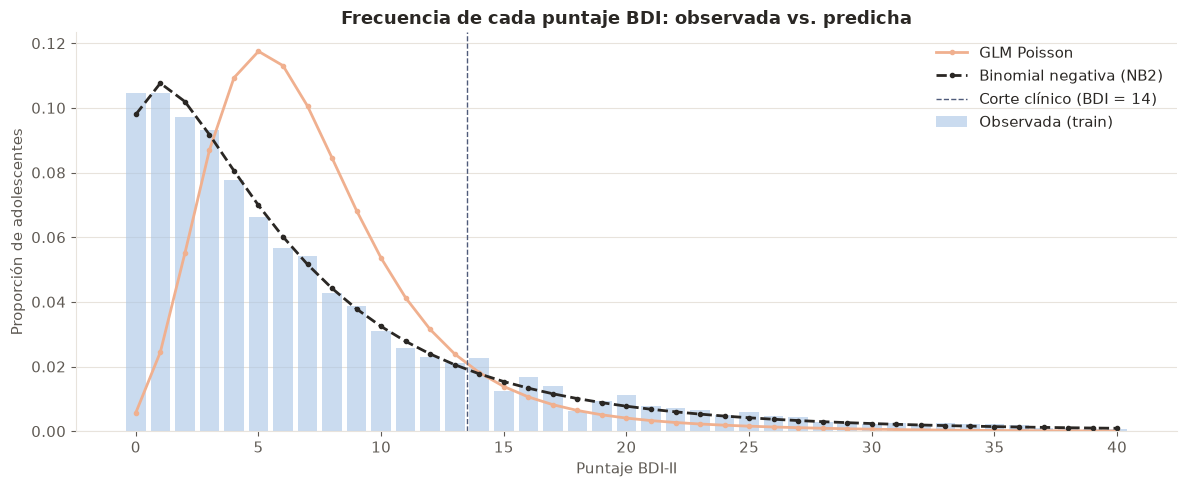

In [14]:
probabilidades = {
    "GLM Poisson": probabilidades_conteo(pruebas["modelo_poisson"].mu),
    "Binomial negativa (NB2)": probabilidades_conteo(np.asarray(pruebas["modelo"].predict()), alpha=pruebas["modelo"].params["alpha"]),
}
fig = graficar_frecuencias_conteo(y_train, probabilidades)
plt.show()

La binomial negativa reproduce casi exactamente la distribución observada: la proporción de ceros (9.8% predicha frente a 10.5% observada), el descenso progresivo desde 0 y la cola derecha más allá del corte clínico. El Poisson, en cambio, pone un pico ficticio en 4–6 puntos y casi ningún cero.

### Conclusión: ¿Poisson o Binomial Negativa?

La conclusión se basa en la prueba LR (con el p-valor corregido por el borde), en el AIC y el BIC, y en qué modelo reproduce mejor la distribución observada del BDI (sobre todo los ceros y la cola derecha).

In [15]:
Markdown(pruebas["conclusion"])

La binomial negativa es más apropiada para el BDI: alpha = 0.715 es claramente mayor que 0 (LR = 10964.8, p corregido = 0) y tiene menor AIC y BIC. La varianza del BDI crece más rápido que su media (Var = μ + α·μ²), así que el Poisson subestima los errores estándar.

### Conclusiones

- Para describir el BDI, la binomial negativa es claramente más apropiada que el Poisson. alpha = 0.715 (IC: 0.675 a 0.755), la prueba LR la favorece (LR = 10,965, p corregido ≈ 0), su AIC y su BIC son unos 10,960 puntos menores, y reproduce la distribución observada, incluidos los ceros y la cola.
- Sus razones de tasas confirman los mismos efectos que OLS y el Poisson (calidad del sueño, sexo, duración del sueño y tiempo de pantalla), con IC entre 2.5 y 3.3 veces más anchos que los del Poisson.
- Como predictor de la media, sin embargo, es el peor modelo de la fase 1 (RMSE de CV = 7.164; R² = 0.136). Describir mejor la distribución no implica mejores predicciones puntuales: la binomial negativa es la mejor opción para la inferencia (coeficientes e IC), pero no para minimizar el RMSE.